# Predicting Bridge Performance under Earthquakes with Supervised Learning
**UE24CS352A – Machine Learning · Mini-Project**

Binary classification: predict whether a bridge is **damaged (1)** or **undamaged (0)** from bridge **age**, earthquake **magnitude** and **distance to epicenter**, using Logistic Regression, QDA and KNN.

Dataset and original approach: public Stanford CS229 (Fall 2018) project by Ziyang Jiang and Xiao Zhang (https://github.com/jzy95310/CS229-Fall-2018-Final-Report). Run this notebook from the repository root (the folder containing `Data/`).

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.utils import resample
from sklearn.linear_model import LogisticRegression
from sklearn.discriminant_analysis import QuadraticDiscriminantAnalysis
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import accuracy_score

np.random.seed(0)   # reproducible bootstrap (original scripts are unseeded, so their numbers vary slightly)

## 1. Load the data
Columns: `x2` = bridge age (yr), `x4` = magnitude, `x5` = distance to epicenter (miles), `y1` = damaged (1) / not (0).

In [2]:
def load(path):
    d = np.genfromtxt(path, delimiter=',', skip_header=1, usecols=range(4))
    d = d[~np.isnan(d).any(axis=1)]
    return d[:, :3], d[:, 3]

X_train, y_train = load('Data/ds2_x2_x4_x5_train.csv')
X_test,  y_test  = load('Data/ds2_x2_x4_x5_test.csv')
X_ktrain, y_ktrain = load('Data/KNN_optimal/ds2_knn_train.csv')
X_cv,     y_cv     = load('Data/KNN_optimal/ds2_knn_cv.csv')

for name, y in [('train', y_train), ('test', y_test), ('KNN-train', y_ktrain), ('validation', y_cv)]:
    print(f'{name:11s} n={len(y):3d}  damaged={int(y.sum()):2d}  undamaged={int((y==0).sum()):3d}')

train       n=199  damaged=18  undamaged=181
test        n= 50  damaged= 3  undamaged= 47
KNN-train   n=149  damaged=14  undamaged=135
validation  n= 50  damaged= 4  undamaged= 46


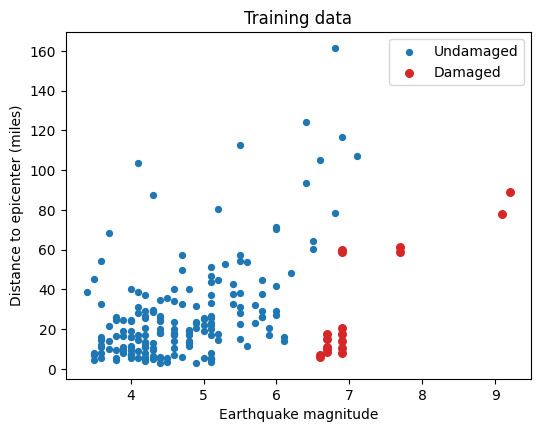

In [3]:
plt.figure(figsize=(6,4.5))
plt.scatter(X_train[y_train==0,1], X_train[y_train==0,2], c='tab:blue', s=18, label='Undamaged')
plt.scatter(X_train[y_train==1,1], X_train[y_train==1,2], c='tab:red',  s=30, label='Damaged')
plt.xlabel('Earthquake magnitude'); plt.ylabel('Distance to epicenter (miles)')
plt.title('Training data'); plt.legend(); plt.show()

## 2. Bootstrap resampling and model evaluation
The damaged class is rare (~1:11), so damaged training examples are **up-sampled with replacement** so that #positive / #negative ∈ {0.2, 0.4, 0.6, 0.8, 1.0}. Each model is trained 100 times per ratio and the accuracies averaged. Accuracy is reported overall and per class.

In [4]:
def run(make_model, Xtr, ytr, Xte, yte, ratios=(0.2,0.4,0.6,0.8,1.0), iters=100):
    pos, neg = Xtr[ytr==1], Xtr[ytr==0]
    res = np.zeros((len(ratios), 4, iters))   # train, test, test-damaged, test-undamaged
    for r, ratio in enumerate(ratios):
        n_s = int(round(ratio * len(neg)))
        for i in range(iters):
            pos_up = resample(pos, replace=True, n_samples=n_s)
            X = np.vstack([pos_up, neg]); y = np.r_[np.ones(n_s), np.zeros(len(neg))]
            m = make_model().fit(X, y)
            p = m.predict(Xte)
            res[r,0,i] = accuracy_score(y, m.predict(X))
            res[r,1,i] = accuracy_score(yte, p)
            res[r,2,i] = accuracy_score(yte[yte==1], p[yte==1])
            res[r,3,i] = accuracy_score(yte[yte==0], p[yte==0])
    return res

models = {
    'Logistic Regression': lambda: LogisticRegression(solver='liblinear'),
    'QDA':                 lambda: QuadraticDiscriminantAnalysis(),
    'KNN (K=2)':           lambda: KNeighborsClassifier(n_neighbors=2),
}
results = {name: run(mk, X_train, y_train, X_test, y_test) for name, mk in models.items()}
print('done')

done


In [5]:
import pandas as pd
rows = []
for name, res in results.items():
    avg = res.mean(axis=2).mean(axis=0)
    rows.append([name] + [f'{100*v:.1f}%' for v in avg])
summary = pd.DataFrame(rows, columns=['Model','Train acc.','Test acc.','Test acc. (damaged)','Test acc. (undamaged)'])
summary

,Model,Train acc.,Test acc.,Test acc. (damaged),Test acc. (undamaged)
0,Logistic Regression,95.4%,74.0%,82.4%,73.4%
1,QDA,97.8%,94.7%,99.9%,94.4%
2,KNN (K=2),99.3%,80.6%,29.7%,83.9%


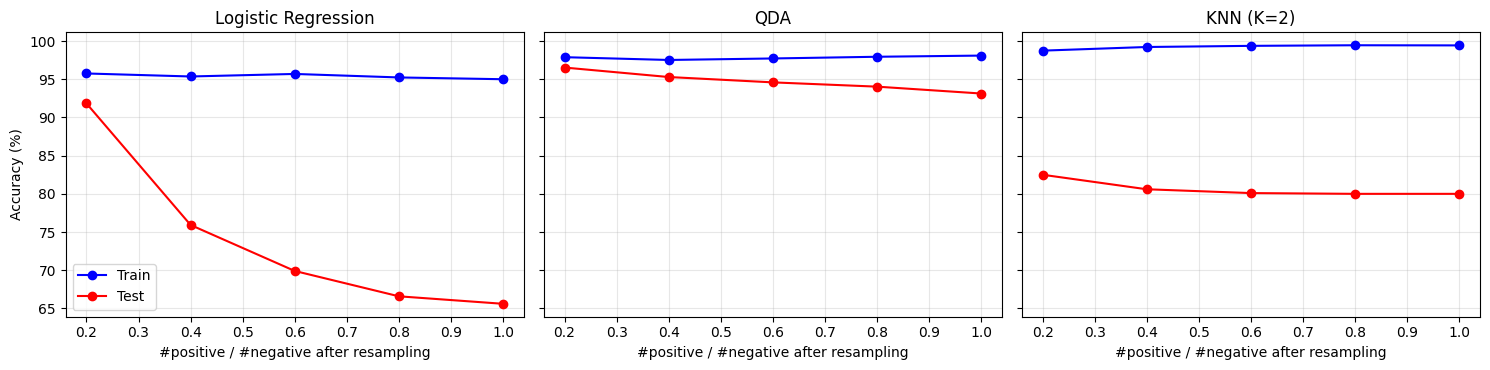

In [6]:
ratios = [0.2,0.4,0.6,0.8,1.0]
fig, axes = plt.subplots(1, 3, figsize=(15,3.8), sharey=True)
for ax, (name, res) in zip(axes, results.items()):
    ax.plot(ratios, 100*res[:,0,:].mean(axis=1), 'o-', color='blue', label='Train')
    ax.plot(ratios, 100*res[:,1,:].mean(axis=1), 'o-', color='red',  label='Test')
    ax.set_title(name); ax.set_xlabel('#positive / #negative after resampling'); ax.grid(alpha=.3)
axes[0].set_ylabel('Accuracy (%)'); axes[0].legend(); plt.tight_layout(); plt.show()

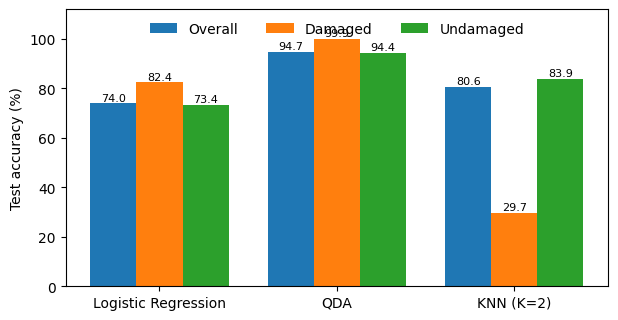

In [7]:
# Per-class test accuracy (the key view for imbalanced data)
names = list(results); x = np.arange(len(names)); w = 0.26
vals = {k: [100*results[n][:,i,:].mean() for n in names] for k, i in [('Overall',1),('Damaged',2),('Undamaged',3)]}
plt.figure(figsize=(7,3.6))
for j, (k, v) in enumerate(vals.items()):
    bars = plt.bar(x+(j-1)*w, v, w, label=k)
    for b, val in zip(bars, v): plt.text(b.get_x()+b.get_width()/2, val+1, f'{val:.1f}', ha='center', fontsize=8)
plt.xticks(x, names); plt.ylim(0,112); plt.ylabel('Test accuracy (%)'); plt.legend(ncol=3, loc='upper center', frameon=False); plt.show()

## 3. Choosing K for KNN
Validation accuracy for K = 1…10, using the same bootstrap procedure on the KNN training split (149 train / 50 validation).

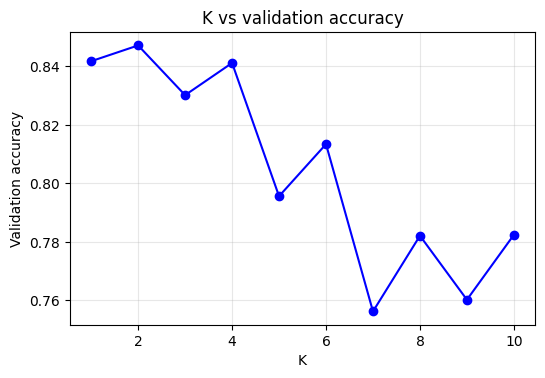

Optimal K = 2


In [8]:
ks = range(1, 11)
cv_acc = [run(lambda k=k: KNeighborsClassifier(n_neighbors=k), X_ktrain, y_ktrain, X_cv, y_cv)[:,1,:].mean() for k in ks]
best_k = int(np.argmax(cv_acc)) + 1
plt.figure(figsize=(6,3.8)); plt.plot(list(ks), cv_acc, 'b-o'); plt.xlabel('K'); plt.ylabel('Validation accuracy')
plt.title('K vs validation accuracy'); plt.grid(alpha=.3); plt.show()
print('Optimal K =', best_k)

## 4. Conclusions
* **QDA is the best model** (~95% test accuracy) and stays stable as more resampled positives are added. Its class-wise Gaussians with separate covariances fit better than a linear boundary.
* **Logistic Regression** under-fits the non-linear boundary, and its test accuracy drops as the resampling ratio increases.
* **KNN** memorises the training data (~99%) but detects only ~30% of damaged test bridges.
* **Limitations:** the test set has only **3 damaged bridges**, so damaged-class accuracies are very coarse; bootstrap resampling adds no new information; "no recorded damage = undamaged" is an assumption.
* **Future work:** more damaged-bridge records, material / structure / traffic features, multi-class damage levels.